# Vision: Beans 이미지 분류 LoRA 실습 — Colab 실행 결과

2026-11-18 Tesla T4에서 실행한 코드와 출력을 보존하고, 실제 결과에 근거한 해석을 추가한 제출 예시입니다. ViT-Small과 Beans를 사용하여 3 Epoch 학습, Test 평가, 결과 ZIP 생성까지 완료했습니다. 다른 실행 환경이나 재실행에서 같은 수치를 보장하지는 않습니다.


## 1. 과제 설정

이미지를 입력받아 다음 세 클래스 중 하나를 예측하는 Image Classification 태스크입니다. 한국어는 이해를 돕는 설명이며 코드의 레이블은 원래 영문을 유지합니다.

| ID | 데이터셋 레이블 | 한국어 설명 |
|---|---|---|
| 0 | angular_leaf_spot | 모무늬병: 잎에 각진 반점이 나타나는 병 |
| 1 | bean_rust | 녹병 |
| 2 | healthy | 건강한 잎(정상) |


In [1]:
TASK = "Vision"
MODEL_ID = "WinKawaks/vit-small-patch16-224"
DATASET_ID = "AI-Lab-Makerere/beans"
SEED = 42
OUTPUT_DIR = "./assignment_runs/vision"


ViT-Small은 작은 ViT 모델이며, Beans는 3종 콩잎 분류 데이터입니다. 기존 Train 1,034 / Validation 133 / Test 128 분할을 유지합니다.

[모델](https://huggingface.co/WinKawaks/vit-small-patch16-224) · [데이터](https://huggingface.co/datasets/AI-Lab-Makerere/beans)

ViT-Small은 약 2,210만 Parameters의 모델로, 큰 Vision 모델보다 실습의 계산 부담을 줄이면서 Attention에 LoRA를 적용하는 과정을 확인하기 위해 선택했습니다. Google 직접 배포본이 아닌 timm 가중치의 커뮤니티 변환본입니다. 모델 카드의 라이선스는 Apache 2.0입니다.

Beans는 작은 규모와 세 개의 명확한 클래스, 준비된 평가 분할 때문에 선택했습니다. 데이터셋 카드의 라이선스는 MIT이며 공개 Hub에서 로딩합니다. Test는 학습 및 설정 선택에 사용하지 않습니다.


## 2. 실행 환경 (Vision 예시 전용)

아래 셀은 실제 실행한 설치 코드와 출력입니다. **마지막 출력의 ‘자동 재시작’은 잘못 남은 안내 문구이며, 이 코드에는 세션을 자동 종료하는 명령이 없습니다.** 실행 기록을 보존하기 위해 해당 출력은 수정하지 않았습니다.

새로 실행할 때는 설치 셀만 먼저 실행하고, 완료 후 런타임 메뉴에서 세션을 한 번 다시 시작합니다. 런타임 삭제는 하지 않습니다. 재연결 후 1번 설정 변수 셀부터 설치 셀을 제외한 나머지를 순서대로 실행합니다.

Datasets 5.0.0과 PyArrow 23.0.1, Hub 1.32.0을 함께 사용합니다. Colab 기본 GPU용 torch·torchvision 버전은 유지하며, 양자화 미사용 실습에서 충돌하는 구버전 torchao를 제거합니다. 설치 로그의 ‘이미 설치됨’은 이 실행 당시 환경을 나타내며, 새 기본 런타임에서 최초 설치한 결과라는 뜻은 아닙니다.


In [2]:
import os
import signal
import subprocess
import sys
from importlib.metadata import version
from pathlib import Path

requirements = [
    "transformers==5.23.0", "peft==0.21.3", "accelerate==1.16.0",
    "datasets==5.0.0", "huggingface-hub==1.32.0",
    "fsspec==2025.12.0", "pandas==2.2.3", "Pillow==12.3.0",
    "pyarrow==23.0.1",
]
# Colab이 제공한 GPU용 PyTorch 조합을 유지합니다.
constraints = Path("/content/vision-torch-constraints.txt")
constraints.write_text("\n".join(
    f"{package}=={version(package)}" for package in ("torch", "torchvision")
))

def run_setup(command):
    result = subprocess.run(command, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)
    print(result.stdout, flush=True)
    if result.returncode:
        raise RuntimeError("환경 설정 실패: 바로 위의 실제 오류를 확인하세요.")

install = [sys.executable, "-m", "pip", "install", "-c", str(constraints), *requirements]
run_setup([*install, "--dry-run"])
run_setup(install)
# 이 실습에서 사용하지 않는 구버전 양자화 패키지와의 충돌을 제거합니다.
run_setup([sys.executable, "-m", "pip", "uninstall", "-y", "torchao"])
run_setup([
    sys.executable, "-c",
    "from PIL import Image, ImageDraw, ImageFont; "
    "from transformers import pipeline, Trainer; "
    "from peft import LoraConfig, get_peft_model; "
    "from datasets import load_dataset; "
    "print('새 Python 프로세스 Import 검사 통과')"
])
print("설치 완료. 자동 재시작 후 설치 셀을 제외하고 실행하세요.", flush=True)





새 Python 프로세스 Import 검사 통과

설치 완료. 자동 재시작 후 설치 셀을 제외하고 실행하세요.


In [3]:
import importlib.metadata
import torch
import pandas as pd
from datasets import load_dataset
from transformers import pipeline, set_seed
from peft import LoraConfig, get_peft_model, PeftModel
from transformers import AutoImageProcessor, AutoModelForImageClassification, Trainer, TrainingArguments, default_data_collator
from IPython.display import display

set_seed(SEED)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "없음")
for package in ("torch", "transformers", "datasets", "peft", "accelerate"):
    print(package, importlib.metadata.version(package))


GPU: Tesla T4
torch 2.14.1+cu130
transformers 5.23.0
datasets 5.0.0
peft 0.21.3
accelerate 1.16.0


## 3. 데이터 로딩과 분할

load_dataset으로 데이터를 불러와 Dataset 또는 DatasetDict를 반환합니다. 분할 이름이 다르면 train / validation / test로 맞춥니다. 제공된 함수가 기존 분할을 유지하고 없는 분할만 생성합니다. 분할이 없으면 80% / 10% / 10%로 나눕니다.

분할 결과의 크기와 클래스 분포를 확인합니다. 같은 화자·원본을 묶어야 하는 데이터에는 무작위 분할 대신 그룹별 분할을 적용합니다.

동일 RGB 픽셀과 크기를 가진 이미지의 해시를 비교합니다. 이 검사는 완전히 같은 이미지만 검출하며, 다른 각도·크롭 등 유사 이미지나 같은 잎의 재촬영까지 배제하지는 못합니다.


In [4]:
from datasets import Dataset, DatasetDict

def prepare_splits(data, seed=SEED):
    splits = DatasetDict({"train": data}) if isinstance(data, Dataset) else DatasetDict(data)
    if "train" not in splits:
        raise ValueError("학습용 분할의 이름을 train으로 지정하세요.")
    if "test" not in splits:
        split = splits["train"].train_test_split(test_size=0.1, seed=seed)
        splits["train"], splits["test"] = split["train"], split["test"]
        validation_ratio = 1 / 9
    else:
        validation_ratio = 0.1
    if "validation" not in splits:
        split = splits["train"].train_test_split(test_size=validation_ratio, seed=seed)
        splits["train"], splits["validation"] = split["train"], split["test"]
    return DatasetDict({name: splits[name] for name in ("train", "validation", "test")})

def load_data():
    """반환: Dataset 또는 train을 포함한 DatasetDict."""
    return load_dataset(DATASET_ID)

raw = prepare_splits(load_data())
print(raw)
print(raw["train"][0])

from hashlib import sha256
from itertools import combinations

def image_fingerprint(image):
    rgb = image.convert("RGB")
    return sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()

fingerprints = {}
for split_name, data in raw.items():
    fingerprints[split_name] = {image_fingerprint(row["image"]) for row in data}
    print(split_name, "클래스 분포:", pd.Series(data["labels"]).value_counts().sort_index().to_dict())
    print("분할 내부 동일 픽셀 중복 수:", len(data) - len(fingerprints[split_name]))
for left, right in combinations(raw.keys(), 2):
    overlap = len(fingerprints[left] & fingerprints[right])
    print(f"{left} / {right} 동일 이미지: {overlap}개")
    assert overlap == 0, "분할 간 동일 이미지가 있습니다. 누출을 해결한 뒤 학습하세요."


README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
{'image_file_path': '/home/albert/.cache/huggingface/datasets/downloads/extracted/967f0d9f61a7a8de58892c6fab6f02317c06faf3e19fba6a07b0885a9a7142c7/train/angular_leaf_spot/angular_leaf_spot_train.0.jpg', 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=500x500 at 0x7B8B7A5016A0>, 'labels': 0}
train 클래스 분포: {0: 345, 1: 348, 2: 341}
분할 내부 동일 픽셀 중복 수: 0
validation 클래스 분포: {0: 44, 1: 45, 2: 44}
분할 내부 동일 픽셀 중복 수: 0
test 클래스 분포: {0: 43, 1: 43, 2: 42}
분할 내부 동일 픽셀 중복 수: 0
train / validation 동일 이미지: 0개
train / test 동일 이미지: 0개
validation / test 동일 이미지: 0개


## 4. 모델과 전처리

RGB 이미지에 같은 Processor를 적용합니다. Beans에 맞는 3-class Head는 새로 초기화합니다. 출력되는 크기 불일치 경고는 기존 1,000-class Head를 교체하기 때문에 예상되는 경고입니다.

Processor 설정에 따라 크기 조정·픽셀 스케일 변환·채널별 정규화를 수행합니다. 구체적인 크기·평균·표준편차는 아래 Processor 출력에 기록됩니다. 학습과 평가에 같은 전처리를 사용하고, 이 기본 예시에는 무작위 증강을 적용하지 않습니다.


In [5]:
labels = raw["train"].features["labels"].names
id2label = dict(enumerate(labels))
label2id = {label: i for i, label in id2label.items()}

def load_model_and_processor():
    processor = AutoImageProcessor.from_pretrained(MODEL_ID, use_fast=False)
    model = AutoModelForImageClassification.from_pretrained(
        MODEL_ID, num_labels=len(labels), id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True)
    return model, processor

model, processor = load_model_and_processor()

def preprocess(example):
    pixels = processor(images=example["image"].convert("RGB"), return_tensors="np")["pixel_values"][0]
    return {"pixel_values": pixels, "labels": example["labels"]}

prepared = raw.map(preprocess, remove_columns=raw["train"].column_names,
                   writer_batch_size=16)
prepared.set_format("torch")
print(prepared["train"][0]["pixel_values"].shape, id2label)
assert tuple(prepared["train"][0]["pixel_values"].shape) == (3, 224, 224)

print(processor)


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.
[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: WinKawaks/vit-small-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([3, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Map:   0%|          | 0/1034 [00:00<?, ? examples/s]

Map:   0%|          | 0/133 [00:00<?, ? examples/s]

Map:   0%|          | 0/128 [00:00<?, ? examples/s]

torch.Size([3, 224, 224]) {0: 'angular_leaf_spot', 1: 'bean_rust', 2: 'healthy'}
ViTImageProcessorPil {
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}



Head를 새로 초기화하므로 학습 전 Accuracy는 무작위 Head의 영향을 받습니다. 전후 변화는 LoRA와 Head를 함께 학습한 결과입니다.


## 5. 학습 전 평가

pipeline 결과의 클래스 이름을 정수 레이블로 변환합니다. Test 전체의 Accuracy와 샘플별 예측을 기록합니다.


In [6]:
def get_targets(test_data):
    """반환: Test 순서대로 정답 레이블을 담은 list."""
    return list(test_data["labels"])

def predict_labels(current_model, processor, test_data):
    """반환: Test 순서대로 예측 레이블을 담은 list."""
    current_model.eval()
    # ViT 클래스의 pipeline 호환성을 유지하며 삽입된 LoRA를 그대로 사용합니다.
    base = current_model.get_base_model() if isinstance(current_model, PeftModel) else current_model
    classifier = pipeline("image-classification", model=base, image_processor=processor,
                          device=0 if torch.cuda.is_available() else -1)
    images = [example["image"].convert("RGB") for example in test_data]
    outputs = classifier(images, batch_size=8, top_k=1)
    return [label2id[output[0]["label"]] for output in outputs]

def accuracy(targets, predictions):
    if len(targets) == 0 or len(targets) != len(predictions):
        raise ValueError("정답과 예측은 길이가 같고 비어 있지 않아야 합니다.")
    return sum(a == b for a, b in zip(targets, predictions)) / len(targets)

def evaluate_model(current_model, processor, test_data):
    targets = get_targets(test_data)
    predictions = predict_labels(current_model, processor, test_data)
    if len(targets) != len(test_data):
        raise ValueError("Test의 모든 샘플에 대해 정답과 예측을 반환하세요.")
    metrics = {"accuracy": accuracy(targets, predictions)}
    table = pd.DataFrame({"sample_id": range(len(targets)), "target": targets,
                          "prediction": predictions})
    return metrics, table

before_metrics, before = evaluate_model(model, processor, raw["test"])
print(before_metrics)
display(before.head())


{'accuracy': 0.3125}


,sample_id,target,prediction
0,0,0,0
1,1,0,2
2,2,0,0
3,3,0,2
4,4,0,0


## 6. LoRA 적용

모델의 모듈 이름을 확인한 뒤 target_modules, r, lora_alpha 등을 설정합니다. task_type은 해당 PEFT 지원 방식에 맞게 선택합니다. Classification head를 학습해야 한다면 modules_to_save 등 적절한 방법으로 포함하고, 저장 대상도 확인합니다.

In [7]:
def make_lora_config(model):
    names = {name.rsplit(".", 1)[-1] for name, _ in model.named_modules()}
    if {"q_proj", "v_proj"} <= names:
        targets = ["q_proj", "v_proj"]
    elif {"query", "value"} <= names:
        targets = ["query", "value"]
    else:
        raise ValueError("Query/Value 모듈 이름을 model.named_modules()로 확인하세요.")
    print("LoRA 대상:", targets)
    return LoraConfig(r=8, lora_alpha=16, lora_dropout=0.1,
                      target_modules=targets, modules_to_save=["classifier"], bias="none")

lora_config = make_lora_config(model)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()


LoRA 대상: ['q_proj', 'v_proj']
trainable params: 148,611 || all params: 21,815,430 || trainable%: 0.6812


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


Query·Value에 Rank 8 LoRA를 적용합니다. classifier는 학습·저장 대상에 포함하고 나머지 기존 가중치는 고정합니다.

Rank 8과 alpha 16을 기본 실습 설정으로 사용합니다. Query·Value만 선택하여 학습 대상 수를 줄이고, 새 Head도 학습합니다. 이 설정이 최적이라는 뜻은 아니며 Test 성능으로 설정을 선택하지 않습니다.


## 7. 학습

TrainingArguments, Data collator, Trainer를 구성합니다. Train은 학습에, Validation은 설정 선택에 사용합니다. Test는 전달하지 않습니다. Padding·labels 및 Loss가 태스크와 맞는지 확인합니다.
학습률 5e-4, 3 Epoch, Batch size 8, Gradient accumulation 2로 설정합니다. GPU 한 개 기준 유효 Batch size는 16입니다. 매 Epoch Validation Loss와 Accuracy를 확인하며, 이번 예시는 최종 Epoch의 모델을 평가합니다.


In [8]:
def make_trainer(model, processor, train_data, validation_data):
    """반환: train() 메서드를 가진 Trainer. OUTPUT_DIR을 저장 경로로 사용합니다."""
    args = TrainingArguments(
        output_dir=OUTPUT_DIR, learning_rate=5e-4, num_train_epochs=3,
        per_device_train_batch_size=8, per_device_eval_batch_size=8,
        gradient_accumulation_steps=2, eval_strategy="epoch", save_strategy="no",
        fp16=torch.cuda.is_available(), remove_unused_columns=False,
        label_names=["labels"], report_to="none", seed=SEED, logging_steps=20)
    return Trainer(model=model, args=args, train_dataset=train_data,
                   eval_dataset=validation_data, data_collator=default_data_collator,
                   compute_metrics=lambda result: {"accuracy": accuracy(
                       result.label_ids.tolist(), result.predictions.argmax(-1).tolist())})

trainer = make_trainer(model, processor, prepared["train"], prepared["validation"])
trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy
1,0.190423,0.093615,0.969925
2,0.092327,0.069721,0.962406
3,0.036478,0.046548,0.977444


TrainOutput(global_step=195, training_loss=0.1943243498985584, metrics={'train_runtime': 198.9293, 'train_samples_per_second': 15.593, 'train_steps_per_second': 0.98, 'total_flos': 6.111870067150848e+16, 'train_loss': 0.1943243498985584, 'epoch': 3.0})

## 8. 학습 후 평가

학습 전 평가와 동일한 함수·Test 데이터를 사용합니다. 성능 향상이 없거나 실패한 사례도 그대로 기록합니다.

,before,after
accuracy,0.3125,0.953125


,sample_id,target,before,after
0,0,0,0,0
1,1,0,2,0
2,2,0,0,0
3,3,0,2,0
4,4,0,0,0
...,...,...,...,...
123,123,2,0,2
124,124,2,0,2
125,125,2,0,2
126,126,2,0,2


동일한 Test 128개에서 Accuracy는 31.25%에서 95.31%로 변했으며, 변화량은 +64.06%p입니다. 오답에서 정답으로 바뀐 샘플은 85개, 정답에서 오답으로 바뀐 샘플은 3개입니다.
학습 후 클래스별 결과:


,count,mean
target,,
angular_leaf_spot,43,0.930233
bean_rust,43,0.953488
healthy,42,0.976190


학습 후 실제 오분류 사례 (최대 3개):
Test #6: 정답 angular_leaf_spot, 예측 bean_rust


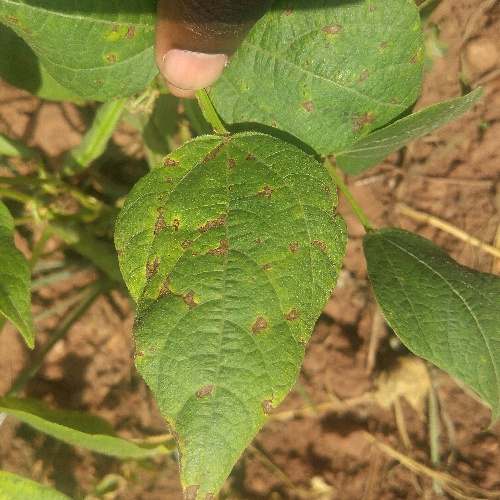

Test #30: 정답 angular_leaf_spot, 예측 bean_rust


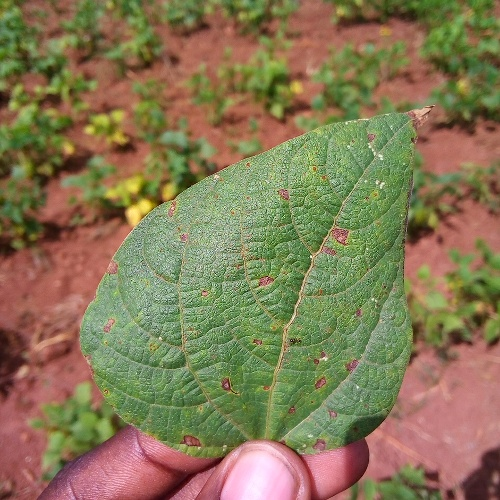

Test #37: 정답 angular_leaf_spot, 예측 bean_rust


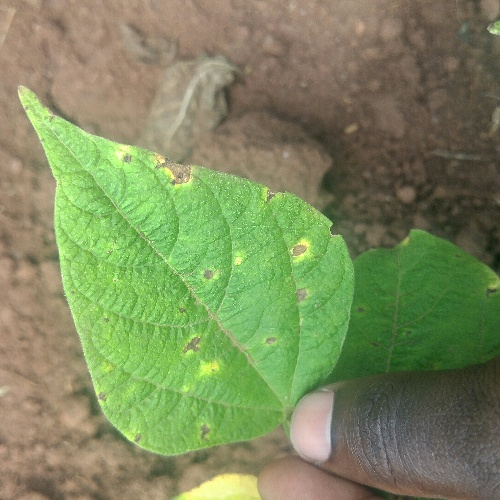

In [9]:
after_metrics, after = evaluate_model(model, processor, raw["test"])
assert len(before) >= 5 and len(after) >= 5, "비교 샘플을 최소 5개 기록하세요."
assert before["sample_id"].is_unique and after["sample_id"].is_unique
assert before[["sample_id", "target"]].reset_index(drop=True).equals(
    after[["sample_id", "target"]].reset_index(drop=True)
), "학습 전후 동일한 샘플·순서·정답을 사용하세요."
comparison = before.rename(columns={"prediction": "before"}).merge(
    after[["sample_id", "prediction"]].rename(columns={"prediction": "after"}),
    on="sample_id", validate="one_to_one"
)
display(pd.DataFrame({"before": before_metrics, "after": after_metrics}))
display(comparison)

delta_pp = (after_metrics["accuracy"] - before_metrics["accuracy"]) * 100
before_correct = comparison["before"] == comparison["target"]
after_correct = comparison["after"] == comparison["target"]
analysis_text = (
    f"동일한 Test {len(comparison)}개에서 Accuracy는 "
    f"{before_metrics['accuracy']:.2%}에서 {after_metrics['accuracy']:.2%}로 변했으며, "
    f"변화량은 {delta_pp:+.2f}%p입니다. "
    f"오답에서 정답으로 바뀐 샘플은 {int((~before_correct & after_correct).sum())}개, "
    f"정답에서 오답으로 바뀐 샘플은 {int((before_correct & ~after_correct).sum())}개입니다."
)
print(analysis_text)
print("학습 후 클래스별 결과:")
display(comparison.assign(correct=after_correct).groupby("target")["correct"].agg(["count", "mean"]).rename(index=id2label))
failures = comparison.loc[~after_correct]
if failures.empty:
    print("이 Test에서는 오분류가 없었습니다. 다른 분포에 대한 일반화를 보장하지는 않습니다.")
else:
    print("학습 후 실제 오분류 사례 (최대 3개):")
    for row in failures.head(3).itertuples(index=False):
        print(f"Test #{row.sample_id}: 정답 {id2label[row.target]}, 예측 {id2label[row.after]}")
        display(raw["test"][row.sample_id]["image"])


## 9. 실행 결과 저장과 다운로드 안내

아래 셀은 Adapter(학습한 Classification head 포함), Processor·모델 설정, 비교 CSV, Accuracy와 분석 문장을 파일로 저장하고 ZIP으로 압축합니다. Base model 가중치와 데이터셋은 포함하지 않습니다. 다운로드는 자동으로 시작되지 않습니다.

1. 셀 실행 후 출력된 ZIP 경로를 확인합니다.
2. Colab 왼쪽 파일 패널을 열고 새로고침합니다.
3. `/content` 아래의 `vision_results_…zip` 파일 메뉴에서 **다운로드**를 선택합니다.
4. 다운로드가 완료되었는지 확인하고 ZIP 전체를 보관합니다. 필요하면 Google Drive에 직접 업로드합니다.

런타임이 삭제되기 전에 다운로드를 완료합니다. 실행 출력이 포함된 노트북은 **파일 → 다운로드 → .ipynb 다운로드**로 별도 저장합니다.


In [10]:
from pathlib import Path
from datetime import datetime, timezone
import json
import shutil

save_dir = (
    Path("/content")
    / f"vision_results_{datetime.now(timezone.utc):%Y%m%dT%H%M%S_%fZ}"
)
adapter_dir = save_dir / "adapter"
save_dir.mkdir(parents=True, exist_ok=False)

model.save_pretrained(adapter_dir)
processor.save_pretrained(adapter_dir)
model.config.save_pretrained(adapter_dir)

comparison.to_csv(save_dir / "comparison.csv", index=False)

(save_dir / "results.json").write_text(
    json.dumps(
        {
            "base_model": MODEL_ID,
            "dataset": DATASET_ID,
            "seed": SEED,
            "before": before_metrics,
            "after": after_metrics,
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

(save_dir / "analysis.txt").write_text(analysis_text, encoding="utf-8")

zip_path = shutil.make_archive(str(save_dir), "zip", root_dir=save_dir)
print("결과 폴더:", save_dir)
print("파일 패널에서 다운로드할 ZIP:", zip_path)


결과 폴더: /content/vision_results_20261118T125557_761716Z
파일 패널에서 다운로드할 ZIP: /content/vision_results_20261118T125557_761716Z.zip


### 실제 실행 결과 해석

#### 학습 전후 비교

| 항목 | 학습 전 | 학습 후 |
|---|---:|---:|
| Test Accuracy | 31.25% | 95.31% |
| Test 정답 수 | 40 / 128 | 122 / 128 |
| Test 오답 수 | 88 / 128 | 6 / 128 |

Accuracy는 **64.06%p 상승**했습니다. 오답에서 정답으로 바뀐 샘플은 85개였지만, 정답에서 오답으로 바뀐 샘플도 3개 있었습니다. 전체 정답 수는 82개 늘었으며, 모든 샘플의 예측이 개선된 것은 아닙니다.

학습 전에는 Beans용 Classification head가 무작위로 초기화된 상태였습니다. 따라서 이 비교는 이미 학습된 이미지 특징 추출 부분에 새 Head를 연결한 상태와, LoRA 및 Head를 함께 학습한 상태의 비교입니다. 성능 향상을 LoRA만의 효과라고 해석할 수는 없습니다. 이를 분리하려면 Head만 학습하는 대조 실험이 필요합니다.

#### 클래스별 결과와 실패 사례

| 클래스 | 정답 / 전체 | 클래스별 정답률 |
|---|---:|---:|
| angular_leaf_spot (모무늬병) | 40 / 43 | 93.02% |
| bean_rust (녹병) | 41 / 43 | 95.35% |
| healthy (정상) | 41 / 42 | 97.62% |

위 정답률은 각 실제 클래스의 샘플 중 맞힌 비율로, 클래스별 Recall에 해당합니다. 이번 Test에서는 모무늬병 클래스가 가장 낮았습니다. 출력된 Test #6, #30, #37은 모두 모무늬병인데 녹병으로 예측됐습니다. 이는 실제로 관찰된 혼동이며, 조명·배경·병변 모양 중 어떤 요소가 원인인지는 출력만으로 확정할 수 없습니다. 세 클래스 모두 샘플 수가 작아 이 순위를 일반적인 난이도 순위로 해석하지 않습니다.

#### 학습 과정과 효율

| Epoch | 기록된 Training Loss | Validation Loss | Validation Accuracy |
|---|---:|---:|---:|
| 1 | 0.190423 | 0.093615 | 96.99% |
| 2 | 0.092327 | 0.069721 | 96.24% |
| 3 | 0.036478 | 0.046548 | 97.74% |

Training Loss 열은 Trainer 표에 출력된 로깅 값이며 Epoch 전체 평균이라고 해석하지 않습니다. Validation Loss는 세 Epoch 동안 감소했고 Accuracy는 2 Epoch에서 소폭 하락한 뒤 마지막에 가장 높았습니다. 이 기록에서는 학습이 진행될수록 Validation Loss가 상승하는 뚜렷한 과적합 징후는 보이지 않습니다. 최종 Test Accuracy는 Validation보다 약 2.43%p 낮지만, 이 차이만으로 과적합 여부를 단정할 수 없습니다.

Tesla T4에서 195 Step, 3 Epoch 학습에 약 **198.93초(3분 19초)**가 걸렸습니다. 이는 Trainer가 기록한 학습 구간의 시간이며 다운로드·전처리·Test 평가·ZIP 생성 시간은 포함하지 않습니다. 학습 가능한 Parameters는 **148,611개**, 전체 21,815,430개의 **0.6812%**였습니다. 이 수에는 LoRA와 새 Classification head가 포함됩니다. Full fine-tuning 대조 실험이나 GPU 최대 메모리 측정은 하지 않았으므로 구체적인 속도·메모리 절감률을 주장할 수는 없습니다.

#### 데이터 확인과 한계

Train 1,034개, Validation 133개, Test 128개의 공식 분할을 유지했습니다. 각 분할 내부와 분할 사이에서 동일 RGB 픽셀 이미지 중복은 0개였습니다. 다만 같은 잎의 다른 촬영이나 크롭·압축 변화가 있는 유사 이미지까지 배제한 검사는 아닙니다.

작은 Test 데이터와 단일 Seed의 결과이므로 다른 촬영 환경이나 작물에서도 95.31%의 정확도를 보장하지 않습니다. 후속 실험에서는 Test를 설정 선택에 사용하지 않고, Validation을 통해 설정을 비교하거나 여러 Seed와 별도 촬영 데이터로 결과의 안정성을 확인할 수 있습니다.

#### 저장 결과

실행 로그에서 Adapter 폴더, 비교 CSV, 결과 JSON, 분석 텍스트를 저장하고 ZIP 경로를 출력한 것까지 확인했습니다. 파일을 실제 PC로 다운로드했는지와 저장한 Adapter를 다시 로딩했을 때의 결과는 이 실행 기록에 포함되어 있지 않습니다.

과제 제출 파일은 **이 설명과 실행 출력이 포함된 `.ipynb` 하나**입니다. Adapter와 ZIP은 재사용을 위한 보관용이며 별도 제출 대상이 아닙니다.
